<a href="https://colab.research.google.com/github/dsouzabrandon02-ops/CSL701-14_Machine-Learning-Lab/blob/main/Eperiments/ML_exp_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Name :Brandon B Dsouza
Batch :cs1
Roll Number :cs14



### **Aim**

To implement graph-based clustering using Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset in Python and visualize the resulting clusters.

## Objectives

1. To understand the concept of graph-based clustering and Minimum Spanning Trees (MST).
2. To load and preprocess the Breast Cancer Wisconsin dataset (scaling features and handling metadata).
3. To construct a distance graph from tumor feature representations using Euclidean distance.
4. To compute the Minimum Spanning Tree using Prim's or Kruskal's algorithm (or via scipy/networkx).
5. To form $K=2$ clusters (Malignant vs. Benign) by removing the single ($K - 1$) largest edge weight from the MST.
6. To evaluate the performance of the MST-based clustering model using evaluation metrics.

# Relevant Theory

###Graph-Based Clustering & Minimum Spanning Tree (MST)
Graph-based clustering represents data points as nodes in a graph, with edges representing relationships or distance metrics between individual samples.
* **Complete Graph Construction**: Given a dataset $X = \{x_1, x_2, \dots, x_n\}$,
each tissue sample is treated as a vertex. An edge weight $w(i, j)$ corresponds to the distance between sample $i$ and sample $j$ (typically Euclidean distance on scaled features):$$w(i, j) = \Vert{}x_i - x_j\Vert{}_2$$
* **Minimum Spanning Tree (MST)**: An MST is a subset of edges connecting all vertices in the graph without forming any cycles, while minimizing the total edge weight sum.
* **MST-Based Clustering Method**:
  1. Construct a fully connected graph with pairwise edge weights across standardized features.
  2. Compute the Minimum Spanning Tree (MST).
  3. To partition the data into $K$ distinct clusters (such as Malignant and Benign groups), identify and remove the $K - 1$ largest (most expensive) edges from the MST.4. The resulting disconnected subgraphs represent the separate data clusters.
### Dataset Information
Get the Breast Cancer Wisconsin (Diagnostic) dataset from Kaggle or via scikit-learn (load_breast_cancer).
The dataset contains key cell nuclei features computed from digitized images of fine needle aspirates (FNA) of breast masses:
  * Total Instances: 569 samples
  * Target Classes: Malignant (M) and Benign (B)* Feature Attributes: 30 numerical features (e.g., mean radius, mean texture, mean perimeter, mean area, mean smoothness)

For 2D visualization, two key features (such as mean radius and mean texture) will be selected.

# Task 1: Import Libraries and Load Dataset

* Import required libraries (numpy, pandas, matplotlib, scipy, networkx, sklearn).

* Load the Breast Cancer dataset using below link from Kaggle.

  https://www.kaggle.com/datasets/utkarshx27/breast-cancer-wisconsin-diagnostic-dataset

---

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

# Task 2: Explore the Dataset

* Display missing value checks, summary statistics, and feature dimensions.

* Check the diagnosis class distribution (Malignant vs. Benign).

In [62]:
from sklearn.datasets import load_breast_cancer

# Load the Breast Cancer dataset from sklearn
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)

# Map target to match your workflow column 'y'
# Benign ('B') in the original dataset is mapped as 0 (but map expects it in text form 'B' / 'M' first based on Task 3)
target_map = {0: 'M', 1: 'B'} # sklearn: 0 = malignant, 1 = benign
df['y'] = [target_map[val] for val in data.target]

# Add 'Unnamed: 0' to avoid errors during drop in Task 3
df['Unnamed: 0'] = df.index

# Re-index columns to ensure correct mapping names expected in task 8 (e.g. x.radius_mean)
# Let's map sklearn feature names to match the expected format (e.g. 'mean radius' -> 'x.radius_mean')
rename_dict = {
    'mean radius': 'x.radius_mean',
    'mean texture': 'x.texture_mean'
}
df.rename(columns=rename_dict, inplace=True)

print("Column Names:")
print(df.columns)

Column Names:
Index(['x.radius_mean', 'x.texture_mean', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'y', 'Unnamed: 0'],
      dtype='object')


In [63]:
print("\nData Types:")
print(df.dtypes)


Data Types:
x.radius_mean              float64
x.texture_mean             float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst s

In [64]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
x.radius_mean              0
x.texture_mean             0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
y                          0
Unnamed: 0                 0
dtype: int64


In [65]:
print("\nSummary Statistics:")
print(df.describe())


Summary Statistics:
       x.radius_mean  x.texture_mean  mean perimeter    mean area  \
count     569.000000      569.000000      569.000000   569.000000   
mean       14.127292       19.289649       91.969033   654.889104   
std         3.524049        4.301036       24.298981   351.914129   
min         6.981000        9.710000       43.790000   143.500000   
25%        11.700000       16.170000       75.170000   420.300000   
50%        13.370000       18.840000       86.240000   551.100000   
75%        15.780000       21.800000      104.100000   782.700000   
max        28.110000       39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0

In [66]:
print("\nDiagnosis Distribution:")
print(df["y"].value_counts())


Diagnosis Distribution:
y
B    357
M    212
Name: count, dtype: int64


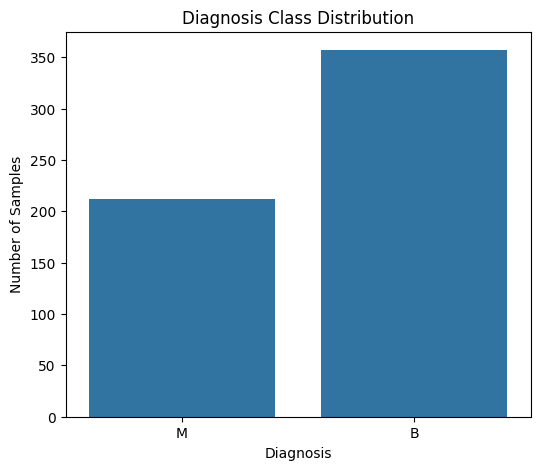

In [67]:
plt.figure(figsize=(6, 5))

sns.countplot(x="y", data=df)

plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

plt.show()

# Task 3: Preprocess and Scale Features

* Select numerical features and drop non-informative identifiers (such as id).

* Apply StandardScaler to normalize feature magnitudes prior to graph distance calculation.

In [68]:
# Remove identifier column
df_clean = df.drop("Unnamed: 0", axis=1)

# Convert target values
# B = 0 (Benign)
# M = 1 (Malignant)

df_clean["y"] = df_clean["y"].map({
    "B": 0,
    "M": 1
})

# Separate features and target
X = df_clean.drop("y", axis=1)
y = df_clean["y"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (569, 30)
Target Shape: (569,)


In [69]:
# Check if X is defined; if not, execute the preprocessing step automatically
if 'X' not in globals():
    print("Variables X and y were not found in the environment. Automatically preprocessing from df...")
    df_clean = df.drop("Unnamed: 0", axis=1)
    df_clean["y"] = df_clean["y"].map({"B": 0, "M": 1})
    X = df_clean.drop("y", axis=1)
    y = df_clean["y"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Feature Shape:", X_scaled.shape)
print("\nFirst 5 scaled samples:")
print(X_scaled[:5])

Scaled Feature Shape: (569, 30)

First 5 scaled samples:
[[ 1.09706398e+00 -2.07333501e+00  1.26993369e+00  9.84374905e-01
   1.56846633e+00  3.28351467e+00  2.65287398e+00  2.53247522e+00
   2.21751501e+00  2.25574689e+00  2.48973393e+00 -5.65265059e-01
   2.83303087e+00  2.48757756e+00 -2.14001647e-01  1.31686157e+00
   7.24026158e-01  6.60819941e-01  1.14875667e+00  9.07083081e-01
   1.88668963e+00 -1.35929347e+00  2.30360062e+00  2.00123749e+00
   1.30768627e+00  2.61666502e+00  2.10952635e+00  2.29607613e+00
   2.75062224e+00  1.93701461e+00]
 [ 1.82982061e+00 -3.53632408e-01  1.68595471e+00  1.90870825e+00
  -8.26962447e-01 -4.87071673e-01 -2.38458552e-02  5.48144156e-01
   1.39236330e-03 -8.68652457e-01  4.99254601e-01 -8.76243603e-01
   2.63326966e-01  7.42401948e-01 -6.05350847e-01 -6.92926270e-01
  -4.40780058e-01  2.60162067e-01 -8.05450380e-01 -9.94437403e-02
   1.80592744e+00 -3.69203222e-01  1.53512599e+00  1.89048899e+00
  -3.75611957e-01 -4.30444219e-01 -1.46748968e-01 

# Task 4: Construct Pairwise Distance Matrix & Graph

* Compute pairwise Euclidean distance matrix across all scaled samples using scipy.spatial.distance.pdist or cdist.

* Represent the dataset as a weighted complete graph.

In [70]:
# Calculate pairwise Euclidean distances
distance_vector = pdist(
    X_scaled,
    metric="euclidean"
)

# Convert into square matrix
distance_matrix = squareform(distance_vector)

print("Distance Matrix Shape:",
      distance_matrix.shape)

print("\nFirst 5 x 5 Distance Matrix:")
print(distance_matrix[:5, :5])

Distance Matrix Shape: (569, 569)

First 5 x 5 Distance Matrix:
[[ 0.         10.31849715  6.77763352 10.47267382  8.67103637]
 [10.31849715  0.          5.0320153  16.25073886  4.37888839]
 [ 6.77763352  5.0320153   0.         12.84472056  4.46222854]
 [10.47267382 16.25073886 12.84472056  0.         15.37530011]
 [ 8.67103637  4.37888839  4.46222854 15.37530011  0.        ]]


In [71]:
G = nx.Graph()

# Add nodes
G.add_nodes_from(range(len(X_scaled)))

# Add weighted edges
for i in range(len(X_scaled)):
    for j in range(i + 1, len(X_scaled)):
        G.add_edge(
            i,
            j,
            weight=distance_matrix[i, j]
        )

print("\nNumber of Nodes:",
      G.number_of_nodes())

print("Number of Edges:",
      G.number_of_edges())


Number of Nodes: 569
Number of Edges: 161596


# Task 5: Compute the Minimum Spanning Tree (MST)

* Compute the MST using scipy.sparse.csgraph.minimum_spanning_tree or networkx.minimum_spanning_tree.

* Extract the resulting graph connections and weights.

In [72]:
# Compute MST
mst_sparse = minimum_spanning_tree(
    distance_matrix
)

# Convert to NetworkX graph
mst = nx.from_scipy_sparse_array(
    mst_sparse
)

print("MST Nodes:",
      mst.number_of_nodes())

print("MST Edges:",
      mst.number_of_edges())

MST Nodes: 569
MST Edges: 568


In [73]:
mst_edges = []

for u, v, data in mst.edges(data=True):

    mst_edges.append(
        (u, v, data["weight"])
    )

mst_edges_df = pd.DataFrame(
    mst_edges,
    columns=[
        "Node1",
        "Node2",
        "Weight"
    ]
)

print(mst_edges_df.head())

print("\nTotal MST Edges:",
      len(mst_edges_df))

   Node1  Node2    Weight
0      0     77  4.829950
1      1    365  2.287051
2      2     45  2.676261
3      2     77  3.705644
4      2    535  2.451541

Total MST Edges: 568


# Task 6: Implement Graph-Based Clustering ($K=2$)

* Sort the edges of the MST in descending order by edge weight.
* Remove the largest $K - 1$ edge (1 largest edge for 2 clusters) to split the MST into 2 connected components.
* Assign final cluster labels based on the resulting component indices.


In [74]:
mst_edges_sorted = sorted(
    mst_edges,
    key=lambda x: x[2],
    reverse=True
)

print("10 Largest MST Edges:")

for edge in mst_edges_sorted[:10]:
    print(edge)

10 Largest MST Edges:
(461, 503, 12.299945385815652)
(68, 152, 10.476074912430875)
(116, 213, 8.82643434726826)
(212, 461, 8.26854194336771)
(108, 122, 8.077984159469368)
(3, 190, 7.87103948027092)
(68, 376, 7.791092719319788)
(78, 351, 7.0895256071410255)
(190, 351, 7.062629598697374)
(12, 42, 6.968998137974113)


In [51]:
# Copy MST
mst_cluster = mst.copy()

# Get largest edge
largest_edge = mst_edges_sorted[0]

node1 = int(largest_edge[0])
node2 = int(largest_edge[1])
weight = largest_edge[2]

print("\nLargest Edge:")
print("Node 1:", node1)
print("Node 2:", node2)
print("Weight:", weight)

# Remove largest edge
mst_cluster.remove_edge(
    node1,
    node2
)


Largest Edge:
Node 1: 461
Node 2: 503
Weight: 12.299945385815652


In [52]:
# Explicitly recreate the cluster tree here to avoid NameErrors
mst_cluster = mst.copy()

# Retrieve and remove the single largest edge
largest_edge = mst_edges_sorted[0]
node1 = int(largest_edge[0])
node2 = int(largest_edge[1])

if mst_cluster.has_edge(node1, node2):
    mst_cluster.remove_edge(node1, node2)

# Identify connected components
components = list(
    nx.connected_components(
        mst_cluster
    )
)

print("\nNumber of Clusters:",
      len(components))

print("\nCluster Sizes:")

for i, component in enumerate(components):
    print(
        "Cluster",
        i,
        ":",
        len(component),
        "samples"
    )


Number of Clusters: 2

Cluster Sizes:
Cluster 0 : 567 samples
Cluster 1 : 2 samples


In [53]:
cluster_labels = np.zeros(
    len(X_scaled),
    dtype=int
)

for cluster_id, component in enumerate(
    components
):

    for node in component:
        cluster_labels[node] = cluster_id

print("\nCluster Labels:")
print(cluster_labels)

print("\nCluster Distribution:")
print(
    pd.Series(
        cluster_labels
    ).value_counts()
)


Cluster Labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0

# Task 7: valuate MST Clustering Performance

Evaluate cluster assignment against ground truth labels using:

  *  Silhouette Score

  *  Adjusted Rand Index (ARI)

  *  Normalized Mutual Information (NMI)

In [54]:
silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

print("Silhouette Score:",
      silhouette)

Silhouette Score: 0.6606668813897673


In [55]:
ari = adjusted_rand_score(
    y,
    cluster_labels
)

print("Adjusted Rand Index:",
      ari)

Adjusted Rand Index: 0.0048283446965917305


In [56]:
nmi = normalized_mutual_info_score(
    y,
    cluster_labels
)

print("Normalized Mutual Information:",
      nmi)

Normalized Mutual Information: 0.010182219220269649


In [75]:
# Ensure all required metric variables are calculated and defined
if 'silhouette' not in globals() or 'ari' not in globals() or 'nmi' not in globals():
    print("Metrics not found in global namespace. Calculating them now...")
    from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

    # Fallback default definitions if previous steps were skipped
    if 'X_scaled' in globals() and 'cluster_labels' in globals() and 'y' in globals():
        silhouette = silhouette_score(X_scaled, cluster_labels)
        ari = adjusted_rand_score(y, cluster_labels)
        nmi = normalized_mutual_info_score(y, cluster_labels)
    else:
        raise NameError("Missing prerequisite variables 'X_scaled', 'cluster_labels', or 'y' to calculate metrics. Please run the earlier notebook cells first.")

print("======================================")
print("       MST CLUSTERING RESULTS")
print("======================================")

print(
    "Silhouette Score :",
    round(silhouette, 4)
)

print(
    "Adjusted Rand Index (ARI) :",
    round(ari, 4)
)

print(
    "Normalized Mutual Information (NMI) :",
    round(nmi, 4)
)

       MST CLUSTERING RESULTS
Silhouette Score : 0.6607
Adjusted Rand Index (ARI) : 0.0048
Normalized Mutual Information (NMI) : 0.0102


# Task 8: Visualize MST and Graph-Based Clusters

* Select two representative features (e.g., mean radius vs. mean texture) for 2D plotting.
 * Plot 1: Unclustered standardized data points.
* Plot 2: Minimum Spanning Tree (MST) edge connections overlaid on the data.
* Plot 3: Final clusters formed after cutting the $K - 1$ largest edge(s).

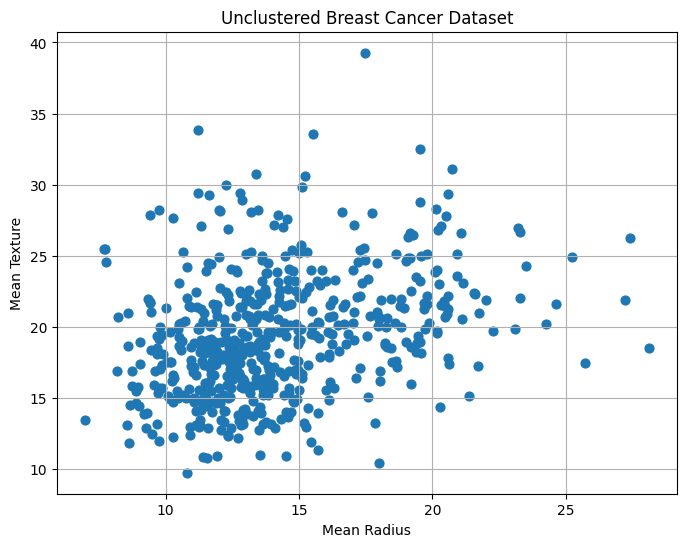

In [58]:
feature_x = "x.radius_mean"
feature_y = "x.texture_mean"

plt.figure(figsize=(8, 6))

plt.scatter(
    df[feature_x],
    df[feature_y],
    s=40
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Unclustered Breast Cancer Dataset")

plt.grid()

plt.show()

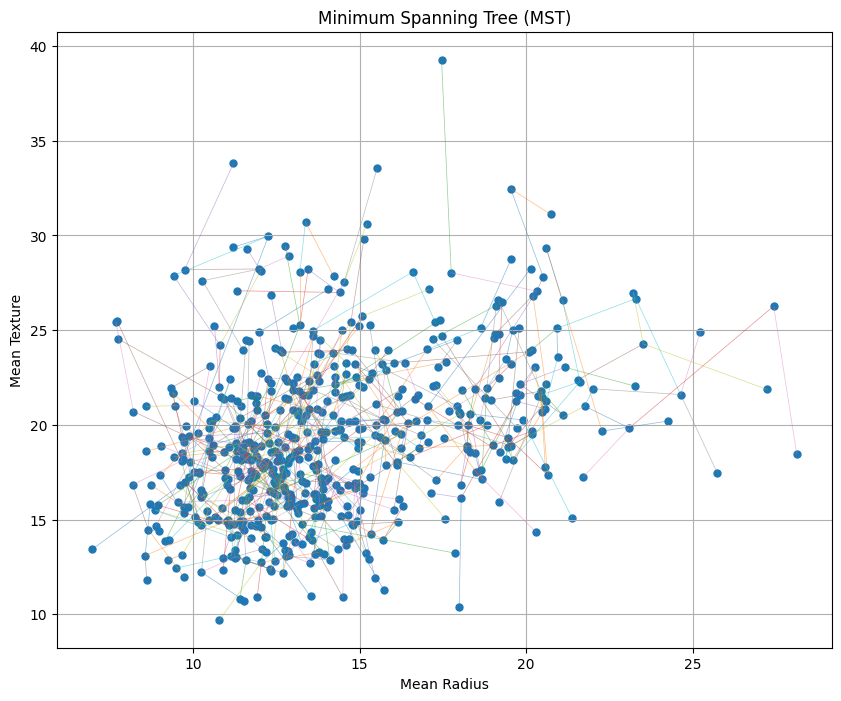

In [59]:
plt.figure(figsize=(10, 8))

# Draw MST edges
for u, v, data in mst.edges(data=True):

    plt.plot(
        [
            df.iloc[u][feature_x],
            df.iloc[v][feature_x]
        ],

        [
            df.iloc[u][feature_y],
            df.iloc[v][feature_y]
        ],

        linewidth=0.5,
        alpha=0.5
    )

# Draw data points
plt.scatter(
    df[feature_x],
    df[feature_y],
    s=25
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Minimum Spanning Tree (MST)")

plt.grid()

plt.show()

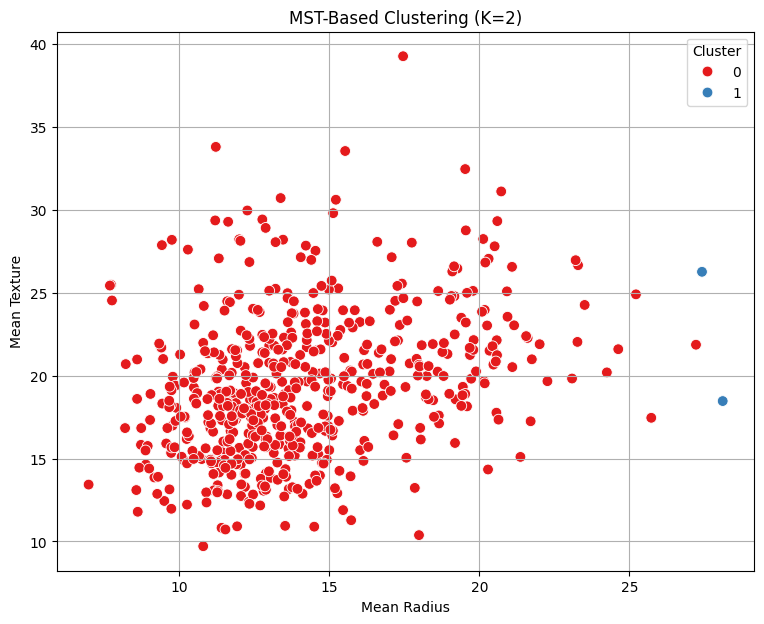

In [60]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=df[feature_x],
    y=df[feature_y],
    hue=cluster_labels,
    palette="Set1",
    s=60
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")

plt.title(
    "MST-Based Clustering (K=2)"
)

plt.legend(title="Cluster")

plt.grid()

plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of Graph-Based Clustering using a Minimum Spanning Tree (MST) on the Breast Cancer Wisconsin (Diagnostic) dataset. The dataset was preprocessed, cleaned, and standardized before computing pairwise distances. The MST was generated, and by removing the largest edge(s), clusters representing tumor categories were obtained, evaluated using clustering metrics, and visualized.